# Block 04 assignment

## Data import

Importing required packages for data handling:

In [6]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import seaborn as sns
from pathlib import Path
import os

Setting project folder as working directory:

In [7]:
proj_dir = Path(os.getcwd()).parent

Sepcifying file locations, then importing `.csv` files:

In [8]:
# ---- File locations ----
files = {
    'CA_Ca3': 'data/processed/AMF_CA-Ca3_FLUXNET_2001-2024_v1.3_r1/AMF_CA-Ca3_FLUXNET_FLUXMET_HH_2001-2024_v1.3_r1.csv',
    'US_Whs': 'data/processed/AMF_US-Whs_FLUXNET_2007-2025_v1.3_r1/AMF_US-Whs_FLUXNET_FLUXMET_HH_2007-2025_v1.3_r1.csv',
    'CN_Nmn': 'data/processed/CNF_CN-Nmn_FLUXNET_2015-2019_v1.3_r1/CNF_CN-Nmn_FLUXNET_FLUXMET_HH_2015-2019_v1.3_r1.csv',
    'FR_Pue': 'data/processed/ICOS_FR-Pue_FLUXNET_2000-2026_v1.3_r1/ICOS_FR-Pue_FLUXNET_FLUXMET_HH_2000-2026_v1.3_r1.csv',
    'AU_Rig': 'data/processed/TERN_AU-Rig_FLUXNET_2011-2017_v1.3_r1/TERN_AU-Rig_FLUXNET_FLUXMET_HH_2011-2017_v1.3_r1.csv'
}

# ---- Reading data from file locations ----
data = {}

for stn in files:
    data[stn] = pd.read_csv(
        proj_dir / files[stn],
        na_values=[-9999],
        dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str}
    )

data_df = pd.concat(data)

# ---- Convert timestamp to datetime format ----
data_df['TIME_START'] = pd.to_datetime(data_df['TIMESTAMP_START'])
data_df['TIME_END'] = pd.to_datetime(data_df['TIMESTAMP_END'])

data_df = data_df.set_index(data_df.index.get_level_values(0))
data_df['station'] = data_df.index

<positron-console-cell-8>:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


## Site overview

Table with information about the five selected FluxNet sites:

| ID | Name | IGBP | Lat | Lon | Years | Hub | Citation |
|---------|---------|---------|---------|---------|---------|---------|---------|
| CA-Ca3 | British Columbia - Pole sapling Douglas-fir stand | ENF | 49.5346 | -124.9004 | 2001-2024 | AmeriFlux | T. Andrew Black (2026), AmeriFlux FLUXNET-1F CA-Ca3 British Columbia - Pole sapling Douglas-fir stand, Ver. v1.3_r1 (2001-2024), AmeriFlux AMP, (Dataset). <https://doi.org/10.17190/AMF/3027312> |
| US-Whs | Walnut Gulch Lucky Hills Shrub | OSH | 31.7438 | -110.0522 | 2007-2025 | AmeriFlux | Russ Scott (2026), AmeriFlux FLUXNET-1F US-Whs Walnut Gulch Lucky Hills Shrub, Ver. v1.3_r1 (2007-2025), AmeriFlux AMP, (Dataset). <https://doi.org/10.17190/AMF/1984574> |
| CN-Nmn | Naiman | CRO | 42.94611 | 120.72694 | 2015-2019 | ChinaFlux | Li, Y. (2026). Fluxnet Archive Product from Naiman, 2015–2019, FLUXNET, <https://hdl.handle.net/11676/0v70myjZ6UGZr9O6hJG55c-t> |
| FR-Pue | Puechabon | EBF | 43.7413 | 3.5957 | 2000-2026 | European Fluxes Database | Limousin, J.-M., Joffre, R., Kempf, J., Ourcival, J.-M., Piquemal, K., Veuillen, L. (2026). Fluxnet Archive Product from Puechabon, 2000-01-01–2026-09-06, FLUXNET, <https://hdl.handle.net/11676/zX4eolqNe8xbcMScyT2IQ9XV> |
| AU-Rig | Riggs Creek | GRA | -36.6499 | 145.5759 | 2011-2017 | OzFlux | Beringer, J., McHugh, I. (2026): Riggs Creek FLUXNET Release 2026_r1 . Version 2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset). |

Map overview of site locations:

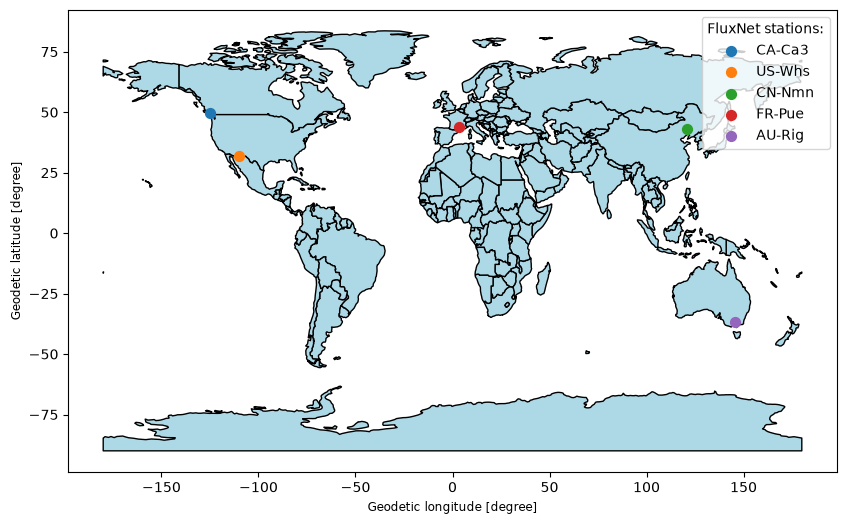

In [9]:
# ---- World map as background ----
world = gpd.read_file(proj_dir / 'data/processed/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')

fig, ax = plt.subplots(figsize=(10, 6))
world.plot(ax=ax, color='lightblue', edgecolor='black')

# ---- Coordinates of selected stations ----
coords = [
    {'lon':-124.9004, 'lat':49.5346, 'stn':'CA-Ca3'},
    {'lon':-110.0522, 'lat':31.7438, 'stn':'US-Whs'},
    {'lon':120.72694, 'lat':42.94611, 'stn':'CN-Nmn'},
    {'lon':3.5957, 'lat':43.7413, 'stn':'FR-Pue'},
    {'lon':145.5759, 'lat':-36.6499, 'stn':'AU-Rig'}
]

# ---- Plot stations into world map ----
for stn in coords:
    gpd.GeoDataFrame(
        geometry=[Point(stn['lon'], stn['lat'])],
        crs='EPSG:4326'
    ).plot(ax=ax, markersize=50, marker='o', label=stn['stn'])

# ---- Show plot ----
plt.legend(title='FluxNet stations:')
plt.show()

## Data coverage

Share of measured NEE (QC 0) per site and year, as a heat map:

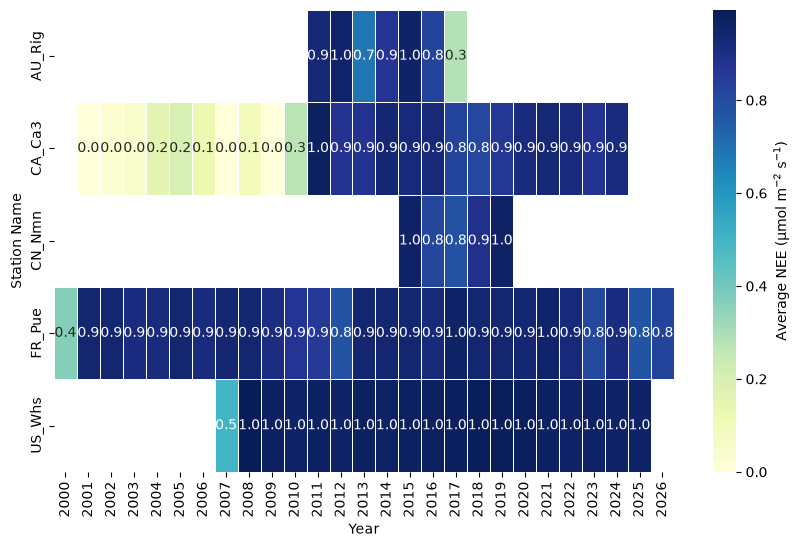

In [17]:
# ---- Extract NEE values from data and calculate yearly averages ----

NEE_df = pd.DataFrame({
    'timestamp':data_df['TIME_START'],
    'value':data_df['NEE_CUT_MEAN_QC'],
    'station':data_df['station']
})
NEE_df['year'] = NEE_df['timestamp'].dt.year

NEE_avg_df = NEE_df.groupby(['year', 'station'])['value'].mean().reset_index()

# ---- Heat map: re-format and plot data ----

heatmap_data = NEE_avg_df.pivot(index='station', columns='year', values='value')

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, 
            annot=True,       # Show the numbers in the cells
            fmt=".1f",        # Format to 1 decimal place
            cmap="YlGnBu",    # Yellow-Green-Blue color palette
            cbar_kws={'label': 'Average NEE ($\\rm \\mu mol~m^{-2}~s^{-1}$)'},
            linewidths=.5)

plt.ylabel('Station Name')
plt.xlabel('Year')
plt.show()

## Summary statistics

Mean, min, max and % missing of TA, SW_IN, VPD, P, NEE, GPP, RECO, H, LE:

In [11]:
# ---- List of variables to be summarized ----
var_list = [
    'TA_F_QC', 'SW_IN_F_QC', 'VPD_F_QC', 'P_F_QC', 'NEE_CUT_MEAN_QC', 'GPP_DT_CUT_MEAN', 'RECO_DT_CUT_MEAN', 'H_F_MDS_QC', 'LE_F_MDS_QC'
]

# ---- Custom function for % missing ----
def isna_mean(x):
    return x.isna().mean()

# ---- Calculating statistics for variables and sites ----
summary = round(data_df.groupby('station')[var_list].agg(['mean', 'min', 'max', isna_mean]), 2)

summary.columns = [f"{var}_{stat}" for var, stat in summary.columns]

print(summary)

         TA_F_QC_mean  TA_F_QC_min  TA_F_QC_max  TA_F_QC_isna_mean  \
station                                                              
AU_Rig           0.26          0.0          2.0               0.00   
CA_Ca3           1.34          0.0          2.0               0.00   
CN_Nmn           0.04          0.0          2.0               0.00   
FR_Pue           0.03          0.0          2.0               0.01   
US_Whs           0.21          0.0          2.0               0.00   

         SW_IN_F_QC_mean  SW_IN_F_QC_min  SW_IN_F_QC_max  \
station                                                    
AU_Rig              0.36             0.0             2.0   
CA_Ca3              0.85             0.0             2.0   
CN_Nmn              0.15             0.0             2.0   
FR_Pue              0.03             0.0             2.0   
US_Whs              0.06             0.0             2.0   

         SW_IN_F_QC_isna_mean  VPD_F_QC_mean  VPD_F_QC_min  ...  \
station              

## Time series

Daily NEE, GPP and RECO aggregated from the half-hourly data:

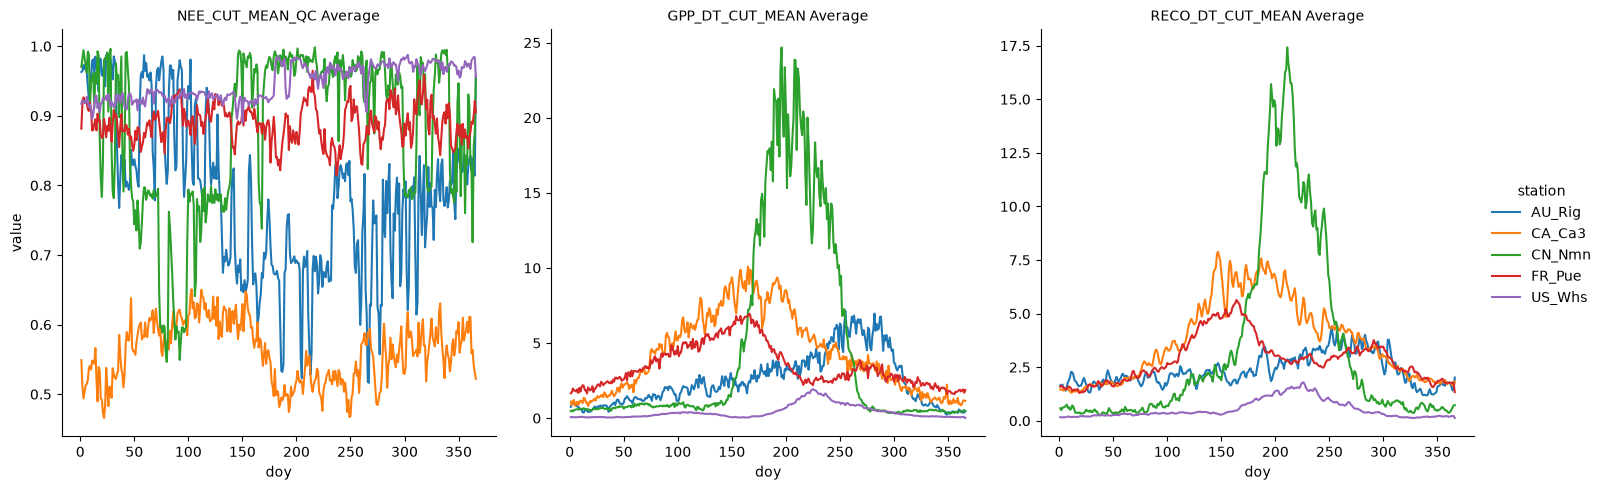

In [19]:
# ---- Aggregaring over DOY ----
data_df['doy'] = data_df['TIME_START'].dt.day_of_year

var_list = ['NEE_CUT_MEAN_QC', 'GPP_DT_CUT_MEAN', 'RECO_DT_CUT_MEAN']
time_series = data_df.groupby(['doy', 'station'])[var_list].mean().reset_index()
time_series = pd.melt(
    time_series,
    id_vars=['doy', 'station'],
    var_name='variable',
    value_name='value'
)

# ---- Subplot for every variable ----
g = sns.relplot(
    data=time_series, x='doy', y='value', 
    hue='station', col='variable', # One subplot per variable
    kind='line', facet_kws={'sharey': False} # Each plot gets its own Y-axis scale
)

g.set_titles('{col_name} Average')

plt.show()

## Diurnal cycles

Mean daily course of NEE and LE per season, all five sites:

<positron-console-cell-13>:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-13>:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


[]

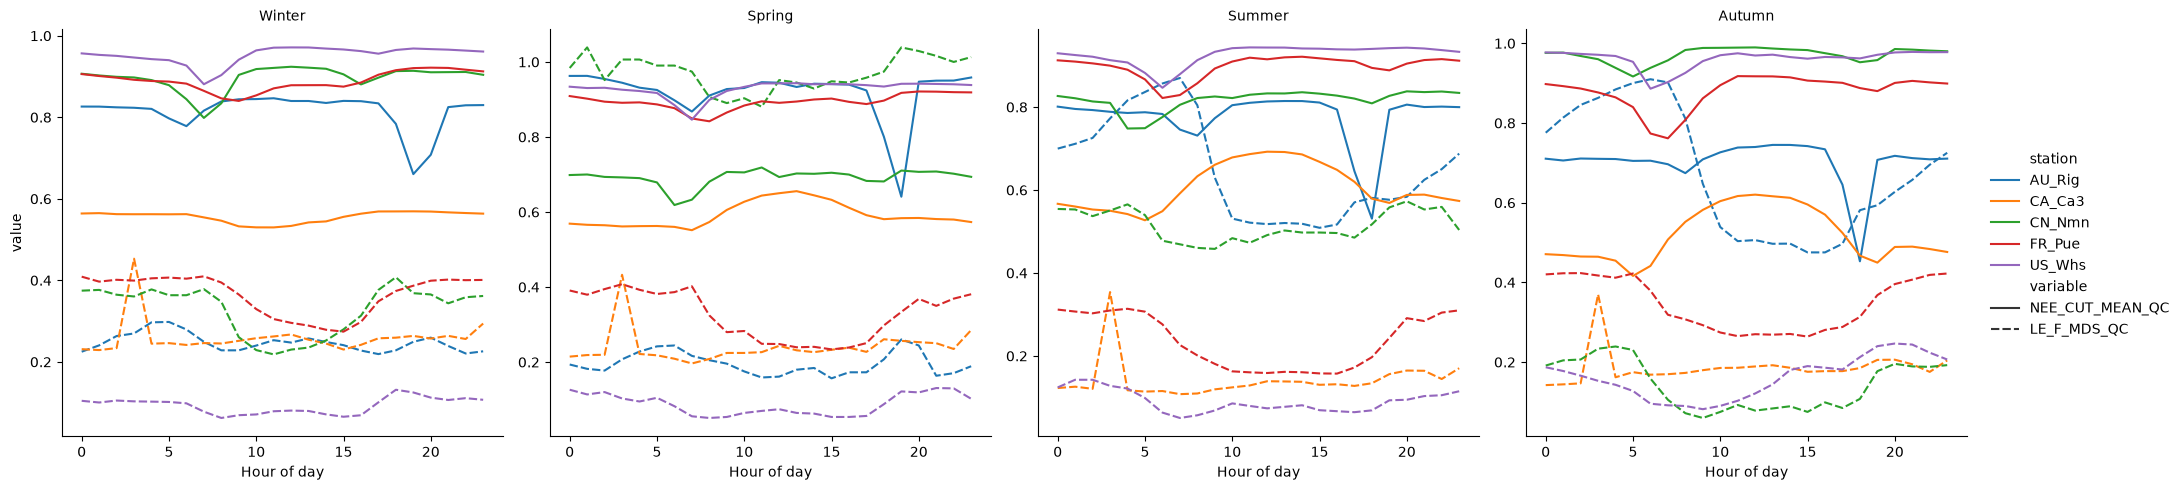

In [13]:
def get_season(doy):
    if 1 <= doy <= 59:        # Jan, Feb
        return 'Winter'
    elif 60 <= doy <= 90:     # Mar
        return 'Spring'
    elif 91 <= doy <= 171:    # Apr, May, Jun
        return 'Summer'
    elif 172 <= doy <= 263:   # Jul, Aug, Sep
        return 'Autumn'
    else:                     # Oct, Nov, Dec
        return 'Winter'

data_df['season'] = data_df['doy'].apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
data_df['season'] = pd.Categorical(data_df['season'], categories=season_order, ordered=True)
data_df['hour'] = data_df['TIME_START'].dt.hour

var_list = ['NEE_CUT_MEAN_QC', 'LE_F_MDS_QC']

diurnal_cycles = data_df.groupby(['station', 'hour', 'season'])[var_list].mean().reset_index()
diurnal_cycles = pd.melt(
    diurnal_cycles,
    id_vars=['station', 'hour', 'season'],
    var_name='variable',
    value_name='value'
)

g = sns.relplot(
    data=diurnal_cycles, x='hour', y='value',
    hue='station', col='season', style='variable',
    kind='line', facet_kws={'sharey': False}
)

g.set_titles('{col_name}')
g.set_xlabels('Hour of day')

plt.plot()

## My reading

Energy balance plot for one site and 5–8 sentences comparing the towers:

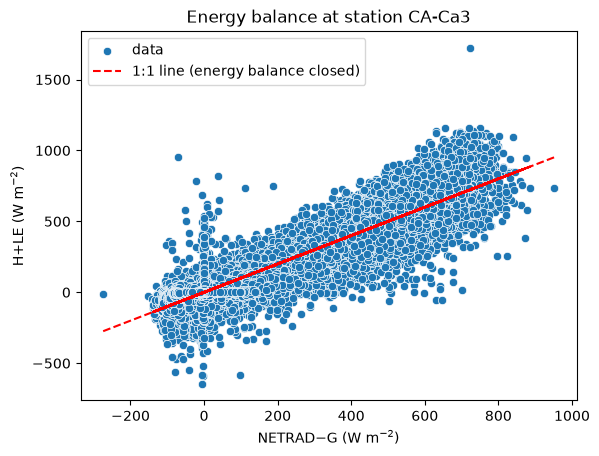

In [21]:
H_LE = data_df['H_CORR'][data_df['station']=='CA_Ca3'] + data_df['LE_CORR'][data_df['station']=='CA_Ca3']
NETRAD_G = data_df['NETRAD'][data_df['station']=='CA_Ca3'] - data_df['G_F_MDS_QC'][data_df['station']=='CA_Ca3']

sns.scatterplot(
    x=list(NETRAD_G),
    y=list(H_LE),
    label='data'
)

plt.plot(NETRAD_G, NETRAD_G, color='red', linestyle='--', label='1:1 line (energy balance closed)')

plt.xlabel('NETRAD$-$G ($\\rm W~m^{-2}$)')
plt.ylabel('H$+$LE ($\\rm W~m^{-2}$)')
plt.title('Energy balance at station CA-Ca3')
plt.legend()
plt.show()

My observations:
- the towers have very different time ranges, making a direct comparison difficult
- NEE is mostly near 1, however at FR-Pue one negative value occurs and at CA-Ca3, values for several years are close to 0
- for GPP and RECO, a clear annual cycle is visible, with CN-Nmn having by far the biggest amplitude; for NEE, no general pattern is observable
- the diurnal cycles of NEE and LE follow similar schemes per site and season, with altered amplitudes
- for CA-Ca3, the average H+LE is very close to a closed energy balance